In [269]:
import torch

class MLPClassifier(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.linear1 = torch.nn.Linear(28 * 28, 256)
        self.linear2 = torch.nn.Linear(256, 64)
        self.linear3 = torch.nn.Linear(64, 10)
        self.activation = torch.nn.ReLU()

    def encode(self, x):
        """Return z representation (64 dimensions), the features before the final classifier."""

        x = torch.flatten(x, start_dim=1)
        x = self.linear1(x)
        x = self.activation(x)
        x = self.linear2(x)
        z = self.activation(x)
        return z

    def forward(self, x):
        z = self.linear3(self.encode(x))
        return z

model = MLPClassifier()

In [270]:
from torchvision.datasets import FashionMNIST
from torchvision.transforms import v2

train_data = FashionMNIST(
    root='data',
    train=True,
    download=True,
    transform=v2.Compose([
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True)
    ])
)

test_data = FashionMNIST(
    root='data',
    train=False,
    download=True,
    transform=v2.Compose([
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True)
    ])
)

In [271]:
from torch.utils.data import random_split
from torch.utils.data import DataLoader

generator = torch.Generator().manual_seed(42)
# train_subset, val_subset = random_split(train_data, [0.8, 0.2], generator=generator)

# train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
# val_loader   = DataLoader(val_subset,   batch_size=64, shuffle=False)
# test_loader  = DataLoader(test_data,    batch_size=64, shuffle=False)

In [272]:
from torch.utils.data import ConcatDataset

full_data = ConcatDataset([train_data, test_data])
train_subset, test_subset, val_subset = random_split(full_data, [0.8, 0.1, 0.1], generator=generator)

In [273]:
train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_subset, batch_size=64, shuffle=False)

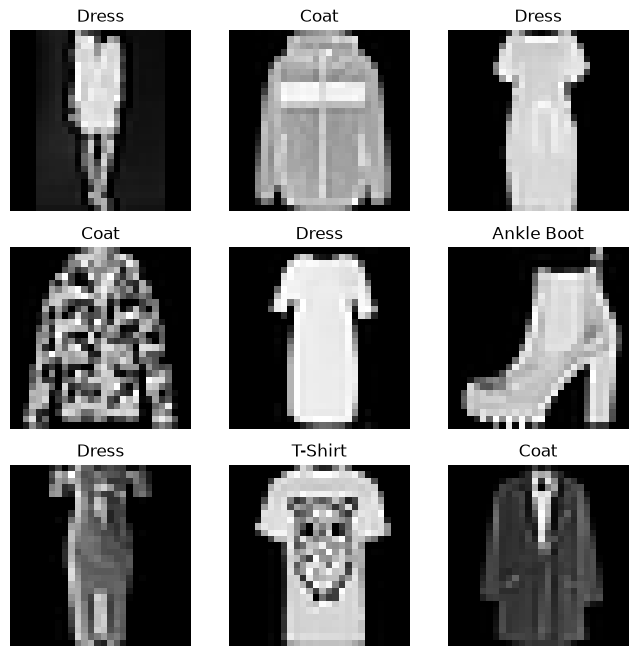

In [274]:
import matplotlib.pyplot as plt

labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(train_data), size=(1,)).item()
    img, label = train_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

In [275]:
loss_fn = torch.nn.CrossEntropyLoss()
epochs = 10
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-8)

In [276]:
images, labels = next(iter(train_loader))
print(images.shape, images.dtype)   # torch.Size([64, 1, 28, 28]), float32
print(labels.shape, labels.dtype)   # torch.Size([64]),            int64

torch.Size([64, 1, 28, 28]) torch.float32
torch.Size([64]) torch.int64


In [278]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
outputs = []
losses = []
model.to(device)

for epoch in range(epochs):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Calculate model prediction loss
        logits = model(images)
        loss = loss_fn(logits, labels)

        # Update parameters
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Update loss
        losses.append(loss.item())
        epoch_loss = sum(losses[-len(train_loader):]) / len(train_loader)

    # Validation
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            correct += (model(images).argmax(1) == labels).sum().item()
            total += labels.size(0)

    outputs.append((epoch, images, logits))
    print(f"Epoch {epoch+1}/{epochs} | Loss: {epoch_loss:.6f}")


Epoch 1/10 | Loss: 0.383534
Epoch 2/10 | Loss: 0.342521
Epoch 3/10 | Loss: 0.315668
Epoch 4/10 | Loss: 0.298304
Epoch 5/10 | Loss: 0.282489
Epoch 6/10 | Loss: 0.271438
Epoch 7/10 | Loss: 0.260847
Epoch 8/10 | Loss: 0.248259
Epoch 9/10 | Loss: 0.237627
Epoch 10/10 | Loss: 0.228949


In [ ]:
# Testing
model.eval()
correct, total_pred = 0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        predictions = model(images).argmax(dim=1)
        correct += (predictions == labels).sum().item()  # jumlah prediksi sesuai label
        total_pred += labels.size(0)  # jumlah label yang ada, gak perlu dijumlah krn emang fix dr awal

        # Older version, will be so long because of iterate over everything
        # for label, prediction in zip(labels, predictions):
        #     if label == prediction:
        #         correct += 1
        #     total_pred += 1

print(f"Accuracy: {correct/total_pred * 100}%")

Accuracy: 88.6%
